# Superhero Intelligence System
## Section 3 · Task 1 · Classification (25 marks)
**Hero or villain? Predict alignment from the 6 ability scores.**

| | |
|---|---|
| Data | Clean Set B (Good → 0 Hero, Bad → 1 Villain) |
| Inputs | the 6 `*_score` columns only |
| Train on | all of train.csv (settings chosen with 5-fold stratified CV) |
| Test on | test.csv, **once**, at the end |
| Main metric | Macro-F1 |
| Models | Baseline (most frequent class) · Decision Tree · KNN |

Not used anywhere: class weights, over/undersampling, extra features, tuning on test.csv.

In [1]:
import os, sys, json
if os.path.basename(os.getcwd()) == "notebooks":   # run from the repo root so data/ paths work
    os.chdir("..")
sys.path.insert(0, os.getcwd())

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_score
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             f1_score, classification_report)

from src.prep import FEATURES, load_raw, clean, xy
from src.style import HERO, VILLAIN, MODEL_COLORS, plot_confusion, save, bar_labels

pd.set_option("display.precision", 3)
RANDOM_STATE = 42

### Step 1 · Load Clean Set B
`X` = the 6 scores (missing values still NaN — the Pipeline fills them), `y` = 0 (Hero) / 1 (Villain).

In [2]:
data = clean(*load_raw())
X_train, y_train = xy(data["set_b_train"])
X_test,  y_test  = xy(data["set_b_test"])     # kept aside - used only in the "Test once" step
print("train:", X_train.shape, " test:", X_test.shape)

train: (916, 6)  test: (225, 6)


**Table T3 · Class counts and % in each file**

In [3]:
def class_table(y):
    n = y.value_counts().reindex([0, 1])
    return pd.DataFrame({"count": n, "%": (100 * n / n.sum()).round(1)})

t3 = pd.concat({"train.csv": class_table(y_train), "test.csv": class_table(y_test)}, axis=1)
t3.index = ["Good (Hero, 0)", "Bad (Villain, 1)"]
t3.loc["Total"] = [len(y_train), 100.0, len(y_test), 100.0]
t3 = t3.astype({("train.csv", "count"): int, ("test.csv", "count"): int})
t3

train.csv        test.csv       
                     count      %    count      %
Good (Hero, 0)         588   64.2      137   60.9
Bad (Villain, 1)       328   35.8       88   39.1
Total                  916  100.0      225  100.0

*T3:* train.csv has 588 heroes and 328 villains (64.2 % / 35.8 %); test.csv has 137 and 88 (60.9 % / 39.1 %). Both files lean about 3 : 2 towards heroes, so the classes are imbalanced but the two files are similar.

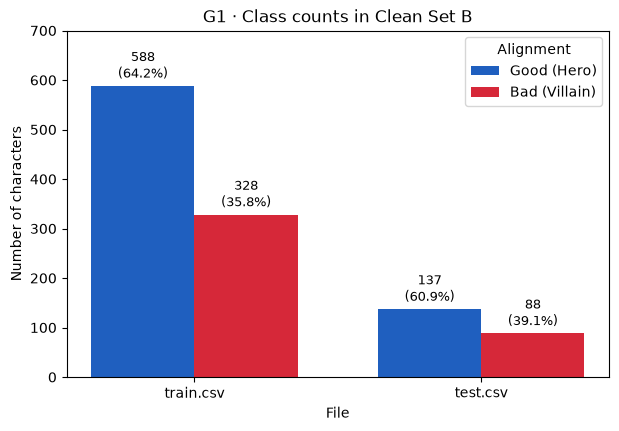

In [4]:
fig, ax = plt.subplots(figsize=(7, 4.5))
files = ["train.csv", "test.csv"]
x = np.arange(len(files)); w = 0.36
for i, (cls, label, colour) in enumerate([(0, "Good (Hero)", HERO), (1, "Bad (Villain)", VILLAIN)]):
    counts = [int((y == cls).sum()) for y in (y_train, y_test)]
    pct = [100 * c / len(y) for c, y in zip(counts, (y_train, y_test))]
    bars = ax.bar(x + (i - 0.5) * w, counts, w, label=label, color=colour)
    for b, c, p in zip(bars, counts, pct):
        ax.annotate(f"{c}\n({p:.1f}%)", (b.get_x() + b.get_width() / 2, c),
                    xytext=(0, 3), textcoords="offset points", ha="center", va="bottom", fontsize=9)
ax.set_xticks(x, files)
ax.set_ylabel("Number of characters")
ax.set_xlabel("File")
ax.set_ylim(0, 700)
ax.set_title("G1 · Class counts in Clean Set B")
ax.legend(title="Alignment")
save(fig, "G01_class_counts.png"); plt.show()

*G1:* heroes outnumber villains roughly 3 : 2 in both files. A model that always says "Hero" would already be right about 61 % of the time on test.csv, which is why accuracy alone is misleading and Macro-F1 is the main metric.

### Steps 2–4 · Pipelines, grid search, refit
| Model | Pipeline | Search | Fixed |
|---|---|---|---|
| Baseline | `DummyClassifier` | — | `strategy="most_frequent"` |
| Decision Tree | median imputer → `DecisionTreeClassifier` | `max_depth` 3, 5, 7, 10, None × `min_samples_leaf` 1, 5, 10 (15) | `criterion="gini"`, `random_state=42` |
| KNN | median imputer → `StandardScaler` → `KNeighborsClassifier` | `n_neighbors` 3, 5, 7, 9, 11, 15 × `weights` uniform, distance (12) | `metric="euclidean"` |

The tree needs no scaling; KNN uses distances, so all 6 scores are standardised. Every setting is scored with 5-fold stratified CV inside train.csv (Macro-F1), and the best one is refitted on all of train.csv (`refit=True`). test.csv is not touched in this step.

In [5]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

baseline = DummyClassifier(strategy="most_frequent", random_state=RANDOM_STATE)
baseline_cv = cross_val_score(baseline, X_train, y_train, cv=cv, scoring="f1_macro")
baseline.fit(X_train, y_train)

dt_search = GridSearchCV(
    Pipeline([("imputer", SimpleImputer(strategy="median")),
              ("model", DecisionTreeClassifier(criterion="gini", random_state=RANDOM_STATE))]),
    {"model__max_depth": [3, 5, 7, 10, None], "model__min_samples_leaf": [1, 5, 10]},
    cv=cv, scoring="f1_macro", refit=True).fit(X_train, y_train)

knn_search = GridSearchCV(
    Pipeline([("imputer", SimpleImputer(strategy="median")),
              ("scaler", StandardScaler()),
              ("model", KNeighborsClassifier(metric="euclidean"))]),
    {"model__n_neighbors": [3, 5, 7, 9, 11, 15], "model__weights": ["uniform", "distance"]},
    cv=cv, scoring="f1_macro", refit=True).fit(X_train, y_train)

print("Decision Tree settings tried:", len(dt_search.cv_results_["params"]))
print("KNN settings tried:          ", len(knn_search.cv_results_["params"]))

Decision Tree settings tried: 15
KNN settings tried:           12


**Table T4 · Best settings and best CV Macro-F1**

In [6]:
def best_row(name, search):
    i = search.best_index_
    params = {k.replace("model__", ""): v for k, v in search.best_params_.items()}
    return {"Model": name, "Best settings": ", ".join(f"{k}={v}" for k, v in params.items()),
            "CV Macro-F1 (mean)": search.cv_results_["mean_test_score"][i],
            "CV Macro-F1 (std)": search.cv_results_["std_test_score"][i]}

t4 = pd.DataFrame([
    {"Model": "Baseline", "Best settings": "strategy=most_frequent (no search)",
     "CV Macro-F1 (mean)": baseline_cv.mean(), "CV Macro-F1 (std)": baseline_cv.std()},
    best_row("Decision Tree", dt_search),
    best_row("KNN", knn_search),
]).set_index("Model")
t4.style.format({"CV Macro-F1 (mean)": "{:.3f}", "CV Macro-F1 (std)": "{:.3f}"})

,Best settings,CV Macro-F1 (mean),CV Macro-F1 (std)
Model,,,
Baseline,strategy=most_frequent (no search),0.391,0.001
Decision Tree,"max_depth=5, min_samples_leaf=10",0.540,0.050
KNN,"n_neighbors=3, weights=uniform",0.517,0.027


*T4:* the best tree is shallow and cautious (max_depth = 5, min_samples_leaf = 10, CV Macro-F1 0.540 ± 0.050) and the best KNN uses k = 3 with uniform votes (0.517 ± 0.027). Both clear the Baseline's 0.391 in cross-validation, but only by 0.13–0.15, a first hint that the six scores carry limited signal about alignment.

*Supporting detail (not a numbered table): every setting's CV score, best first.*

In [7]:
def cv_table(search):
    r = pd.DataFrame(search.cv_results_)
    p = pd.json_normalize(r["params"]).rename(columns=lambda c: c.replace("model__", ""))
    return (pd.concat([p, r[["mean_test_score", "std_test_score", "rank_test_score"]]], axis=1)
              .sort_values("rank_test_score").reset_index(drop=True))

display(cv_table(dt_search))
display(cv_table(knn_search))

,max_depth,min_samples_leaf,mean_test_score,std_test_score,rank_test_score
0,5.0,10,0.540,0.050,1
1,NaN,1,0.526,0.028,2
2,7.0,10,0.524,0.052,3
3,NaN,10,0.518,0.046,4
4,10.0,10,0.514,0.050,5
5,5.0,5,0.514,0.048,6
6,7.0,5,0.508,0.034,7
7,7.0,1,0.506,0.032,8
8,10.0,1,0.501,0.024,9
9,NaN,5,0.488,0.017,10


,n_neighbors,weights,mean_test_score,std_test_score,rank_test_score
0,3,uniform,0.517,0.027,1
1,5,uniform,0.511,0.027,2
2,9,uniform,0.510,0.024,3
3,3,distance,0.509,0.030,4
4,9,distance,0.509,0.034,5
5,5,distance,0.507,0.026,6
6,11,distance,0.506,0.019,7
7,7,uniform,0.504,0.040,8
8,7,distance,0.500,0.029,9
9,15,distance,0.498,0.026,10




### Step 5 · Test once
The three refitted models predict test.csv a single time. "Train Macro-F1" is the final model scored on its own training data (all of train.csv).

In [8]:
models = {
    "Baseline": baseline,
    "Decision Tree": dt_search.best_estimator_,
    "KNN": knn_search.best_estimator_,
}
preds = {name: m.predict(X_test) for name, m in models.items()}          # the only use of test.csv
train_f1 = {name: f1_score(y_train, m.predict(X_train), average="macro") for name, m in models.items()}

for name, p in preds.items():
    print(f"=== {name} · test.csv ===")
    print(classification_report(y_test, p, digits=3, zero_division=0,
                                target_names=["Good (Hero)", "Bad (Villain)"]))

=== Baseline · test.csv ===
               precision    recall  f1-score   support

  Good (Hero)      0.609     1.000     0.757       137
Bad (Villain)      0.000     0.000     0.000        88

     accuracy                          0.609       225
    macro avg      0.304     0.500     0.378       225
 weighted avg      0.371     0.609     0.461       225

=== Decision Tree · test.csv ===
               precision    recall  f1-score   support

  Good (Hero)      0.594     0.876     0.708       137
Bad (Villain)      0.261     0.068     0.108        88

     accuracy                          0.560       225
    macro avg      0.427     0.472     0.408       225
 weighted avg      0.464     0.560     0.473       225

=== KNN · test.csv ===
               precision    recall  f1-score   support

  Good (Hero)      0.629     0.730     0.676       137
Bad (Villain)      0.439     0.330     0.377        88

     accuracy                          0.573       225
    macro avg      0.534    

**Table T5 · Task 1 results** (all on test.csv except the Train column)

In [9]:
rows = []
for name, p in preds.items():
    prec, rec, f1, _ = precision_recall_fscore_support(y_test, p, labels=[0, 1], zero_division=0)
    rows.append({"Model": name, "Train Macro-F1": train_f1[name],
                 "Accuracy": accuracy_score(y_test, p),
                 "Precision Hero": prec[0], "Recall Hero": rec[0], "F1 Hero": f1[0],
                 "Precision Villain": prec[1], "Recall Villain": rec[1], "F1 Villain": f1[1],
                 "Macro-F1": f1_score(y_test, p, average="macro")})
t5 = pd.DataFrame(rows).set_index("Model")
t5.style.format("{:.3f}").highlight_max(subset=["Macro-F1"], color="#DCEBFF")

,Train Macro-F1,Accuracy,Precision Hero,Recall Hero,F1 Hero,Precision Villain,Recall Villain,F1 Villain,Macro-F1
Model,,,,,,,,,
Baseline,0.391,0.609,0.609,1.000,0.757,0.000,0.000,0.000,0.378
Decision Tree,0.563,0.560,0.594,0.876,0.708,0.261,0.068,0.108,0.408
KNN,0.739,0.573,0.629,0.730,0.676,0.439,0.330,0.377,0.526


*T5:* KNN has the best test Macro-F1 (0.526), well ahead of the Decision Tree (0.408) and the Baseline (0.378). The Baseline has the highest accuracy (0.609) only because it calls everyone a hero and finds zero villains, so accuracy would have picked the worst model.

### Step 6 · Report

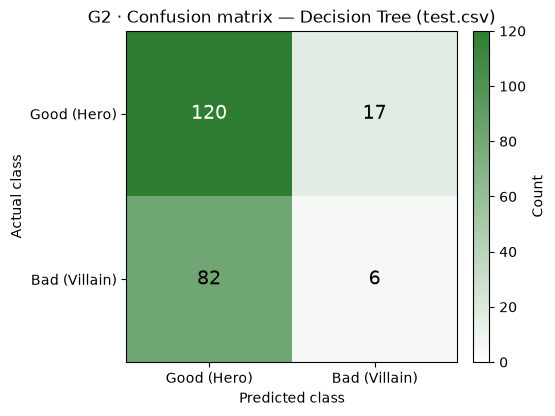

In [10]:
fig, ax = plt.subplots(figsize=(5, 4.3))
plot_confusion(y_test, preds["Decision Tree"], "G2 · Confusion matrix — Decision Tree (test.csv)",
               ax=ax, color=MODEL_COLORS["Decision Tree"])
save(fig, "G02_confusion_decision_tree.png"); plt.show()

*G2:* the tree predicts "Hero" for almost everyone: it labels 120 of 137 heroes correctly but catches only 6 of 88 villains (82 villains missed), so its villain recall is just 0.068.

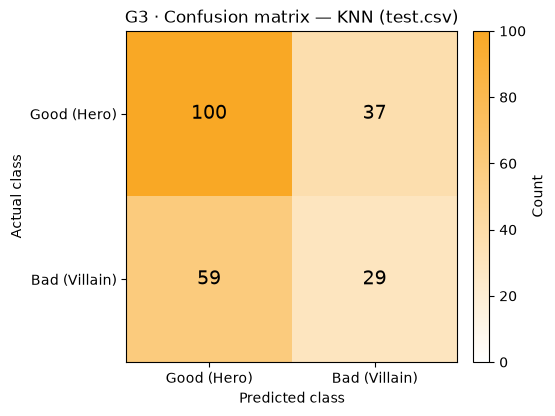

In [11]:
fig, ax = plt.subplots(figsize=(5, 4.3))
plot_confusion(y_test, preds["KNN"], "G3 · Confusion matrix — KNN (test.csv)",
               ax=ax, color=MODEL_COLORS["KNN"])
save(fig, "G03_confusion_knn.png"); plt.show()

*G3:* KNN is more balanced: it catches 29 of 88 villains (recall 0.330) while still labelling 100 of 137 heroes correctly. It is clearly better than the tree at finding villains, but it still misses two out of three.

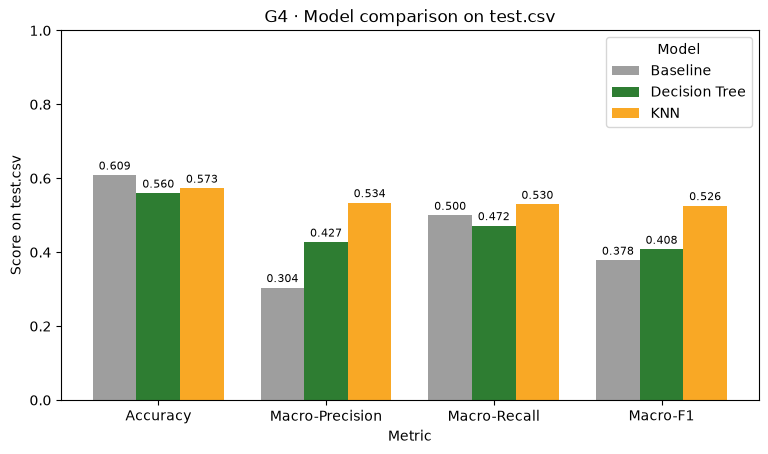

In [12]:
g4 = pd.DataFrame({
    name: {"Accuracy": accuracy_score(y_test, p),
           "Macro-Precision": precision_recall_fscore_support(y_test, p, average="macro", zero_division=0)[0],
           "Macro-Recall": precision_recall_fscore_support(y_test, p, average="macro", zero_division=0)[1],
           "Macro-F1": f1_score(y_test, p, average="macro")}
    for name, p in preds.items()})

fig, ax = plt.subplots(figsize=(9, 4.8))
x = np.arange(len(g4.index)); w = 0.26
for i, name in enumerate(g4.columns):
    bars = ax.bar(x + (i - 1) * w, g4[name], w, label=name, color=MODEL_COLORS[name])
    bar_labels(ax, bars)
ax.set_xticks(x, g4.index)
ax.set_ylim(0, 1)
ax.set_ylabel("Score on test.csv")
ax.set_xlabel("Metric")
ax.set_title("G4 · Model comparison on test.csv")
ax.legend(title="Model")
save(fig, "G04_model_comparison.png"); plt.show()

*G4:* the Baseline wins only on accuracy, because always saying "Hero" is right 61 % of the time. On every macro metric KNN is clearly best, while the tree's Macro-Recall (0.472) is even below the Baseline's 0.500.

### Comparison basis
1. **Winner:** highest test Macro-F1. 2. **Tie-break:** gap < 0.01 → higher Villain recall. 3. **Useful?** only if test Macro-F1 > Baseline's. 4. **Overfitting?** Train Macro-F1 − Test Macro-F1 > 0.10.

In [13]:
base_f1 = t5.loc["Baseline", "Macro-F1"]
checks = t5[["Train Macro-F1", "Macro-F1", "Recall Villain"]].rename(columns={"Macro-F1": "Test Macro-F1"})
checks["Gain over Baseline"] = checks["Test Macro-F1"] - base_f1
checks["Useful? (> Baseline)"] = np.where(checks.index == "Baseline", "-",
                                          np.where(checks["Gain over Baseline"] > 0, "yes", "no"))
checks["Train − Test gap"] = checks["Train Macro-F1"] - checks["Test Macro-F1"]
checks["Overfits? (gap > 0.10)"] = np.where(checks["Train − Test gap"] > 0.10, "yes", "no")

# Winner among the two real models: Macro-F1, then villain recall if the gap is under 0.01
cand = checks.loc[["Decision Tree", "KNN"]].sort_values("Test Macro-F1", ascending=False)
gap = cand["Test Macro-F1"].iloc[0] - cand["Test Macro-F1"].iloc[1]
winner = cand.index[0] if gap >= 0.01 else cand["Recall Villain"].idxmax()
print(f"Macro-F1 gap between the two models: {gap:.3f} -> winner: {winner}"
      + ("" if gap >= 0.01 else " (decided by villain recall)"))
checks.style.format({c: "{:.3f}" for c in checks.columns if checks[c].dtype != object})

Macro-F1 gap between the two models: 0.118 -> winner: KNN


,Train Macro-F1,Test Macro-F1,Recall Villain,Gain over Baseline,Useful? (> Baseline),Train − Test gap,Overfits? (gap > 0.10)
Model,,,,,,,
Baseline,0.391,0.378,0.000,0.000,-,0.013,no
Decision Tree,0.563,0.408,0.068,0.030,yes,0.155,yes
KNN,0.739,0.526,0.330,0.148,yes,0.213,yes


### Answers

**Q1 · Which model wins by the rules?**
**KNN** (k = 3, uniform weights). Its test Macro-F1 is **0.526**, against **0.408** for the Decision Tree. The gap is 0.118, far more than 0.01, so no villain-recall tie-break is needed (KNN would win that too: 0.330 vs 0.068).

**Q2 · Did both models beat the Baseline? By how much?**
Yes, both are above the Baseline's test Macro-F1 of **0.378**, so both count as "useful" by the rule. KNN beats it by **+0.148**; the Decision Tree only by **+0.030**, which is small. Its accuracy (0.560) is actually *lower* than the Baseline's 0.609.

**Q3 · Which class is harder to predict?**
**Villains.** In G2 the tree finds only 6 of 88 villains (recall 0.068, F1 0.108) but 120 of 137 heroes (recall 0.876, F1 0.708). In G3 KNN finds 29 of 88 villains (recall 0.330, F1 0.377) and 100 of 137 heroes (recall 0.730, F1 0.676). Villains are the minority class, and their ability scores overlap heavily with heroes', so both models lean towards predicting "Hero".

**Q4 · Does either model overfit?**
By the rule (Train − Test Macro-F1 > 0.10), **both do**. The Decision Tree drops from 0.563 on train to 0.408 on test (gap 0.155). KNN drops from 0.739 to 0.526 (gap 0.213); with k = 3 each training character is one of its own three nearest neighbours, so its training score is inflated. The tree's test score is also well below its CV score (0.540), so its chosen splits did not generalise to test.csv.

### Save results for Task 3
Task 3 ranks all five models on test.csv (T11, G16), so the Task 1 test results are saved to `results/task1_test.json`.

In [14]:
os.makedirs("results", exist_ok=True)
saved = {}
for name in models:
    p = preds[name]
    prec_m, rec_m, _, _ = precision_recall_fscore_support(y_test, p, average="macro", zero_division=0)
    saved[name] = {
        "test_accuracy": float(t5.loc[name, "Accuracy"]),
        "test_macro_f1": float(t5.loc[name, "Macro-F1"]),
        "test_macro_precision": float(prec_m),
        "test_macro_recall": float(rec_m),
        "villain_recall": float(t5.loc[name, "Recall Villain"]),
        "train_macro_f1": float(t5.loc[name, "Train Macro-F1"]),
        "cv_macro_f1": float(t4.loc[name, "CV Macro-F1 (mean)"]),
        "best_settings": t4.loc[name, "Best settings"],
    }
with open("results/task1_test.json", "w") as f:
    json.dump(saved, f, indent=2)
pd.DataFrame(saved).T[["test_accuracy", "test_macro_f1", "villain_recall"]]

,test_accuracy,test_macro_f1,villain_recall
Baseline,0.609,0.378,0.0
Decision Tree,0.56,0.408,0.068
KNN,0.573,0.526,0.33
